# UAV-VisLoc: локалізація БпЛА по супутниковій карті (папка 06)

**ПІБ:** Солоненко Назар Олегович

**Підхід:**

1. **Embedding.** `facebook/dinov2-base` генерує вектори для супутникових тайлів і для фото з дрона. Використовується **CLS-токен з `last_hidden_state[:, 0, :]`**, вектори L2-нормалізуються, пошук — `faiss.IndexFlatIP` (= cosine similarity), Top-5 кандидатів на фото.
2. **Keypoint matching.** Всередині області навколо Top-1 тайла шукаються відповідності ключових точок через loftr з пошуком серед 5 найкращих кандидатів DinoV2 кандидатів. Шляхом тестування було обрано найоптимальнішу кількість кандидатів, яка давала найбільший приріст метрикам якості, за найменшу затрату по ресурсам.
3. **Fallback.** Якщо keypoint matching не знаходить достатньо inliers, використовується прогноз координат центру Top-1 тайла з embedding.

**Навчання** — Донавчання моделі відсутнє через брак часу та обчислювальних ресурсів Google Colaboratory. Планувалось донавчання Embedding моделі на датасеті з всіх папок окрім 6-ої. Але навіть невелике донавчання займало багато часу для обраної моделі.

**Орієнтовний час виконання повного pipeline:** 20-25 хвилин. Основними витратами є 15-20 хвилин на відбір кандидатів через LoFTR.

In [ ]:
!pip install -q rasterio folium transformers faiss-gpu kaggle==2.2.2 kornia kornia_moons

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 74.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.5/247.5 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 131.9 MB/s eta 0:00:00


In [ ]:
import os
import gc
import random
import time
import numpy as np
import pandas as pd
import cv2
import torch
import rasterio
import faiss
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 667
seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Використовується пристрій: {device}")

Використовується пристрій: cuda


## Завантаження датасету

In [ ]:
import os
import glob

!pip install -q gdown

!gdown --id 1F8k6L7OANSZe_-DCgktQEVBZXsx6cZ1M -O uav-visloc-dataset.zip --fuzzy

!unzip -n uav-visloc-dataset.zip -d UAV-VisLoc/
!rm -f uav-visloc-dataset.zip

csv_paths = glob.glob('/content/UAV-VisLoc/**/06.csv', recursive=True)

assert len(csv_paths) > 0, "Файл 06.csv не знайдено!"

DATA_DIR = os.path.dirname(csv_paths[0])
print(f"\nВстановлено шлях до даних: {DATA_DIR}")

DRONE_DIR = os.path.join(DATA_DIR, 'drone')
GT_CSV_PATH = os.path.join(DATA_DIR, '06.csv')
SAT_MAP_PATH = os.path.join(DATA_DIR, 'satellite06.tif')

assert os.path.exists(DATA_DIR), "Папка з даними не знайдена!"
assert os.path.exists(DRONE_DIR), "Папка з drone-фото не знайдена!"
assert os.path.exists(GT_CSV_PATH), "Файл 06.csv не знайдено!"
assert os.path.exists(SAT_MAP_PATH), "satellite06.tif не знайдено!"

drone_images_number = len(os.listdir(DRONE_DIR))
print(f"Знайдено {drone_images_number} зображень з БпЛА.")
!rm -f uav-visloc-dataset.zip

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1F8k6L7OANSZe_-DCgktQEVBZXsx6cZ1M
From (redirected): https://drive.google.com/uc?id=1F8k6L7OANSZe_-DCgktQEVBZXsx6cZ1M&confirm=t&uuid=433ae591-e8a2-44be-8cdd-198a639cfee4
To: /content/uav-visloc-dataset.zip
100% 694M/694M [00:05<00:00, 135MB/s]
Archive:  uav-visloc-dataset.zip
  inflating: UAV-VisLoc/06.csv       
  inflating: UAV-VisLoc/drone/06_0001.JPG  
  inflating: UAV-VisLoc/drone/06_0002.JPG  
  inflating: UAV-VisLoc/drone/06_0003.JPG  
  inflating: UAV-VisLoc/drone/06_0004.JPG  
  inflating: UAV-VisLoc/drone/06_0005.JPG  
  inflating: UAV-VisLoc/drone/06_0006.JPG  
  inflating: UAV-VisLoc/drone/06_0007.JPG  
  inflating: UAV-VisLoc/drone/06_0008.JPG  
  inflating: UAV-VisLoc/drone/06_0009.JPG  
  inf

## Аналіз датасету

In [ ]:
with rasterio.open(SAT_MAP_PATH) as dataset:
    bounds = dataset.bounds
    MAP_TL_LON, MAP_TL_LAT = bounds.left, bounds.top
    MAP_BR_LON, MAP_BR_LAT = bounds.right, bounds.bottom
    print("Satellite map bounds:")
    print(f"Top-Left: Lat {MAP_TL_LAT:.6f}, Lon {MAP_TL_LON:.6f}")
    print(f"Bottom-Right: Lat {MAP_BR_LAT:.6f}, Lon {MAP_BR_LON:.6f}")

    img_map_rgb = dataset.read([1, 2, 3]).transpose(1, 2, 0)

if img_map_rgb.dtype != np.uint8:
    img_map_rgb = ((img_map_rgb.astype(np.float32) - img_map_rgb.min()) /
                    (img_map_rgb.ptp() + 1e-6) * 255).astype(np.uint8)

map_h, map_w = img_map_rgb.shape[:2]
print(f"Розмір супутникової карти: {map_w} x {map_h} px")

Satellite map bounds:
Top-Left: Lat 32.373177, Lon 109.635160
Bottom-Right: Lat 32.346944, Lon 109.656837
Розмір супутникової карти: 8082 x 9780 px


In [ ]:
gt_coords = pd.read_csv(GT_CSV_PATH)
display(gt_coords.head())

,num,filename,date,lat,lon,height,Omega,Kappa,Phi1,Phi2
0,1,06_0001.JPG,2022-10-09T11:00:05,32.351541,109.646761,838.48,-0.183346,5.443099,173.365570,162.983574
1,2,06_0002.JPG,2022-10-09T11:00:07,32.351025,109.646945,838.79,0.962569,4.761279,174.786505,163.779986
2,3,06_0003.JPG,2022-10-09T11:00:10,32.350498,109.647117,840.01,-0.234913,2.922085,173.314003,163.980521
3,4,06_0004.JPG,2022-10-09T11:00:12,32.349982,109.647289,840.74,-0.246372,1.862113,176.516838,164.822769
4,5,06_0005.JPG,2022-10-09T11:00:15,32.349461,109.647460,839.24,-2.498096,3.678389,174.247925,163.482048


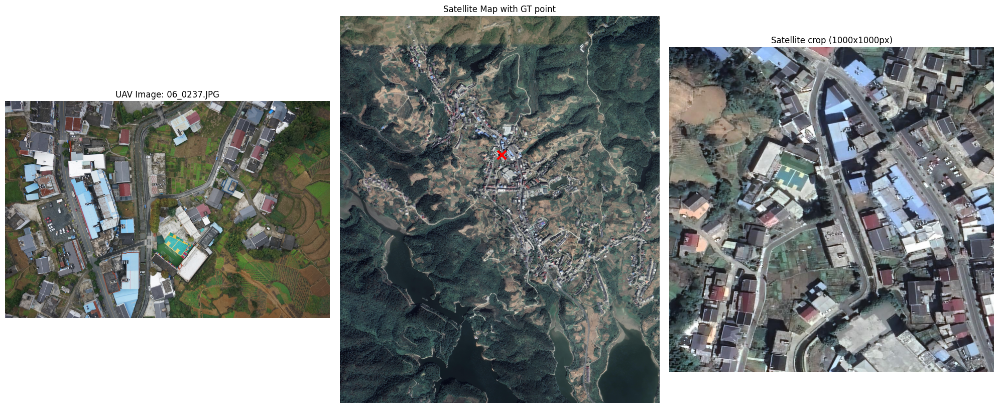

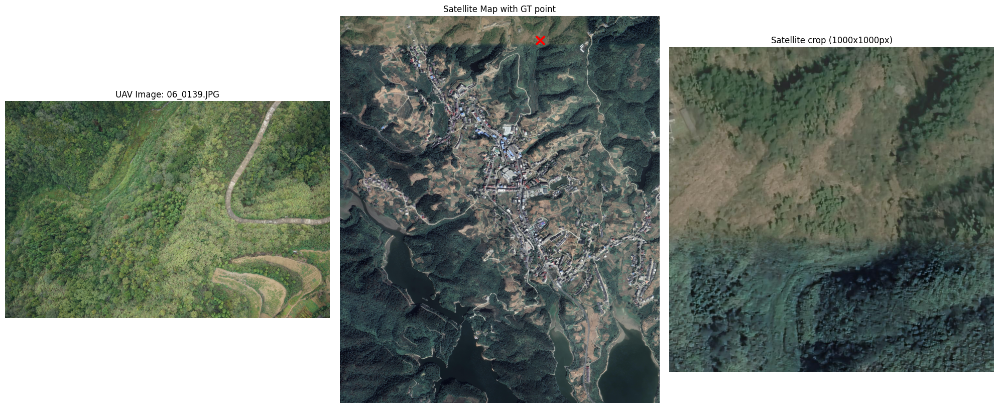

In [ ]:
def show_example(n=0):
    fname = os.listdir(DRONE_DIR)[n]
    drone_img_path = os.path.join(DRONE_DIR, fname)
    row = gt_coords[gt_coords['filename'] == fname].iloc[0]
    gt_lat, gt_lon = row['lat'], row['lon']

    img_drone = cv2.cvtColor(cv2.imread(drone_img_path), cv2.COLOR_BGR2RGB)

    with rasterio.open(SAT_MAP_PATH) as dataset:
        px_y, px_x = dataset.index(gt_lon, gt_lat)

    CROP = 1000
    half = CROP // 2
    y0, y1 = max(0, px_y - half), min(map_h, px_y + half)
    x0, x1 = max(0, px_x - half), min(map_w, px_x + half)
    map_crop = img_map_rgb[y0:y1, x0:x1]

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 8))
    ax1.imshow(img_drone); ax1.set_title(f"UAV Image: {fname}"); ax1.axis('off')
    ax2.imshow(img_map_rgb); ax2.scatter(px_x, px_y, color='red', marker='x', s=150, linewidths=3)
    ax2.set_title("Satellite Map with GT point"); ax2.axis('off')
    ax3.imshow(map_crop); ax3.set_title(f"Satellite crop ({CROP}x{CROP}px)"); ax3.axis('off')
    plt.tight_layout(); plt.show()

show_example(0)
show_example(min(300, len(os.listdir(DRONE_DIR)) - 1))

Як бачимо, між фотографіями з дрону та супутника пройшов час, за який змінилась рослинність, можливо пора року, також кольори та якість між ними сильно відрізняються, як і ракурс, що робить використання класичних методів комп'ютерного зору для пошуку ключових точок неєфективним

## Формування супутникової бази (тайлінг)

In [ ]:
TILE_SIZE = 512
STRIDE = 256
TARGET_SIZE = (224, 224)

tiles = []
tile_coords = []
tile_px_coords = []

print(f"Тайлінг (вікно {TILE_SIZE}x{TILE_SIZE}, крок {STRIDE})...")

with rasterio.open(SAT_MAP_PATH) as dataset:
    for y in tqdm(range(0, map_h - TILE_SIZE + 1, STRIDE)):
        for x in range(0, map_w - TILE_SIZE + 1, STRIDE):
            tile = img_map_rgb[y:y + TILE_SIZE, x:x + TILE_SIZE]
            tile_resized = cv2.resize(tile, TARGET_SIZE)

            center_x = x + TILE_SIZE / 2
            center_y = y + TILE_SIZE / 2
            lon, lat = dataset.xy(center_y, center_x)

            tiles.append(tile_resized)
            tile_coords.append((lat, lon))
            tile_px_coords.append((center_y, center_x))

print(f"Створено {len(tiles)} тайлів розміром {TARGET_SIZE}.")

Тайлінг (вікно 512x512, крок 256)...


  0%|          | 0/37 [00:00<?, ?it/s]

Створено 1110 тайлів розміром (224, 224).


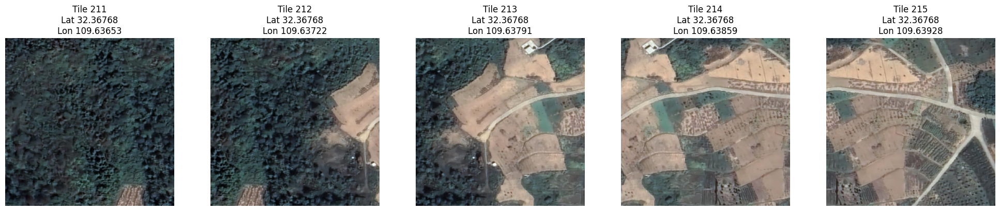

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
idx = random.randint(0, len(tiles) - 5)
for i in range(5):
    axes[i].imshow(tiles[idx + i])
    axes[i].set_title(f"Tile {idx+i}\nLat {tile_coords[idx+i][0]:.5f}\nLon {tile_coords[idx+i][1]:.5f}")
    axes[i].axis('off')
plt.tight_layout(); plt.show()

## Метрика: Haversine Error

In [ ]:
EARTH_RADIUS = 6371000

def haversine_error(gt_lat, gt_lon, pred_lat, pred_lon):
    gt_lat, gt_lon, pred_lat, pred_lon = map(np.radians, [gt_lat, gt_lon, pred_lat, pred_lon])
    a = np.sin((pred_lat - gt_lat) / 2)**2 + np.cos(gt_lat) * np.cos(pred_lat) * np.sin((pred_lon - gt_lon) / 2)**2
    return 2 * EARTH_RADIUS * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

def haversine_matrix(lat1, lon1, lat2, lon2):
    """lat1/lon1: (N,) GT; lat2/lon2: (T,) тайли -> (N,T) метри."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2[None, :] - lat1[:, None]
    dlon = lon2[None, :] - lon1[:, None]
    a = np.sin(dlat / 2)**2 + np.cos(lat1[:, None]) * np.cos(lat2[None, :]) * np.sin(dlon / 2)**2
    return 2 * EARTH_RADIUS * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

print(f"Перевірка формули (Вашингтон → Париж): {haversine_error(38.898, -77.037, 48.858, 2.294):.1f} м")

Перевірка формули (Вашингтон → Париж): 6161438.0 м


## Embedding-модель: DINOv2-base

In [ ]:
MODEL_ID = "facebook/dinov2-base"

print(f"Завантаження моделі: {MODEL_ID}...")
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModel.from_pretrained(MODEL_ID).to(device)
model.eval()
print("Готово.")

Завантаження моделі: facebook/dinov2-base...


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Готово.


In [ ]:
def clear_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def extract_embeddings(image_list, batch_size=32, desc="Генерація векторів"):

    embeddings = []
    pil_images = [Image.fromarray(img) if isinstance(img, np.ndarray) else img for img in image_list]

    i = 0
    with torch.inference_mode():
        pbar = tqdm(total=len(pil_images), desc=desc)
        while i < len(pil_images):
            batch = pil_images[i:i + batch_size]

            inputs = processor(images=batch, return_tensors="pt").to(device)
            outputs = model(**inputs)

            emb = outputs.last_hidden_state[:, 0, :]

            emb_np = emb.float().cpu().numpy()
            emb_np = emb_np / np.linalg.norm(emb_np, axis=1, keepdims=True)
            embeddings.append(emb_np)

            i += batch_size
            pbar.update(len(batch))

        pbar.close()

    return np.vstack(embeddings)

In [ ]:
t0 = time.time()
print("Обробка супутникових тайлів...")
sat_embeddings = extract_embeddings(tiles, batch_size=64, desc="Тайли → вектори")
sat_embed_time = time.time() - t0
clear_memory()
print(f"Час обробки {len(tiles)} тайлів: {sat_embed_time:.1f} c "
      f"({sat_embed_time/len(tiles)*1000:.1f} мс/тайл)")

Обробка супутникових тайлів...


Тайли → вектори:   0%|          | 0/1110 [00:00<?, ?it/s]

Час обробки 1110 тайлів: 21.0 c (19.0 мс/тайл)


In [ ]:
drone_images = []
drone_gt_coords = []
filenames = []

for _, row in tqdm(gt_coords.iterrows(), total=len(gt_coords), desc="Завантаження фото"):
    fname = row['filename']
    img_path = os.path.join(DRONE_DIR, fname)
    img = Image.open(img_path).convert('RGB').resize(TARGET_SIZE)
    drone_images.append(img)
    drone_gt_coords.append((row['lat'], row['lon']))
    filenames.append(fname)

t0 = time.time()
print("Обробка зображень з дрона...")
drone_embeddings = extract_embeddings(drone_images, batch_size=32, desc="Drone → вектори")
drone_embed_time = time.time() - t0
clear_memory()

per_image_ms = drone_embed_time / len(filenames) * 1000
print(f"Час обробки {len(filenames)} фото: {drone_embed_time:.1f} c ({per_image_ms:.1f} мс/фото)")

Завантаження фото:   0%|          | 0/344 [00:00<?, ?it/s]

Обробка зображень з дрона...


Drone → вектори:   0%|          | 0/344 [00:00<?, ?it/s]

Час обробки 344 фото: 4.9 c (14.1 мс/фото)


## Coarse stage: embedding retrieval (FAISS)

In [ ]:
dimension = sat_embeddings.shape[1]
index = faiss.IndexFlatIP(dimension)
index.add(sat_embeddings)

K = 5
similarities, indices = index.search(drone_embeddings, k=K)

gt_coords_arr = np.array(drone_gt_coords)
tile_coords_arr = np.array(tile_coords)

baseline_pred_coords = np.array([tile_coords[indices[i, 0]] for i in range(len(filenames))])
baseline_errors = np.array([
    haversine_error(gt_coords_arr[i, 0], gt_coords_arr[i, 1],
                     baseline_pred_coords[i, 0], baseline_pred_coords[i, 1])
    for i in range(len(filenames))
])

In [ ]:
def compute_metrics(errors, indices, gt_tile_idx, name="baseline"):
    mhe = errors.mean()
    median_err = np.median(errors)
    p90 = np.percentile(errors, 90)
    acc50 = (errors <= 50).mean() * 100
    acc100 = (errors <= 100).mean() * 100
    acc500 = (errors <= 500).mean() * 100
    top1_hit = (indices[:, 0] == gt_tile_idx).mean() * 100
    top5_hit = np.array([gt_tile_idx[i] in indices[i, :5] for i in range(len(gt_tile_idx))]).mean() * 100
    return {
        "Підхід": name,
        "MHE (м)": round(mhe, 2),
        "Median (м)": round(median_err, 2),
        "P90 (м)": round(p90, 2),
        "Acc ≤ 50м (%)": round(acc50, 2),
        "Acc ≤ 100м (%)": round(acc100, 2),
        "Acc ≤ 500м (%)": round(acc500, 2),
        "Top-1 hit (%)": round(top1_hit, 2),
        "Top-5 hit (%)": round(top5_hit, 2),
    }

dist_matrix = haversine_matrix(gt_coords_arr[:, 0], gt_coords_arr[:, 1],
                                tile_coords_arr[:, 0], tile_coords_arr[:, 1])

gt_tile_idx = dist_matrix.argmin(axis=1)

baseline_metrics = compute_metrics(baseline_errors, indices, gt_tile_idx, "DINOv2 embedding retrieval (baseline)")
display(pd.DataFrame([baseline_metrics]))

,Підхід,MHE (м),Median (м),P90 (м),Acc ≤ 50м (%),Acc ≤ 100м (%),Acc ≤ 500м (%),Top-1 hit (%),Top-5 hit (%)
0,DINOv2 embedding retrieval (baseline),798.23,669.51,1580.69,3.49,11.63,41.57,2.03,6.4


## Fine stage: keypoint matching

In [ ]:
import kornia.feature as KF

LOFTR_MATCHER = KF.LoFTR(pretrained='outdoor').to(device).eval()

def _prep_for_loftr(gray_img, size=840):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray_img = clahe.apply(gray_img)

    h, w = gray_img.shape
    scale = size / max(h, w)
    new_h, new_w = max(8, int(round(h * scale / 8) * 8)), max(8, int(round(w * scale / 8) * 8))
    img_r = cv2.resize(gray_img, (new_w, new_h))
    tensor = torch.from_numpy(img_r).float()[None, None] / 255.0
    return tensor.to(device), (w / new_w, h / new_h)

def refine_with_loftr(drone_img_pil, sat_rgb_full, dataset, cand_row, cand_col,
                       search_radius=800, min_inliers=8, conf_thresh=0.2, process_size=840):
    y0, y1 = max(0, cand_row - search_radius), min(sat_rgb_full.shape[0], cand_row + search_radius)
    x0, x1 = max(0, cand_col - search_radius), min(sat_rgb_full.shape[1], cand_col + search_radius)
    sat_crop = sat_rgb_full[int(y0):int(y1), int(x0):int(x1)]

    drone_gray = cv2.cvtColor(np.array(drone_img_pil), cv2.COLOR_RGB2GRAY)
    sat_gray = cv2.cvtColor(sat_crop, cv2.COLOR_RGB2GRAY)
    if sat_gray.shape[0] < 16 or sat_gray.shape[1] < 16:
        return None, None, 0

    t1, scale1 = _prep_for_loftr(drone_gray, process_size)
    t2, scale2 = _prep_for_loftr(sat_gray, process_size)

    with torch.inference_mode():
        out = LOFTR_MATCHER({"image0": t1, "image1": t2})

    kp1 = out["keypoints0"].cpu().numpy()
    kp2 = out["keypoints1"].cpu().numpy()
    conf = out["confidence"].cpu().numpy()

    keep = conf > conf_thresh
    kp1, kp2 = kp1[keep], kp2[keep]
    if len(kp1) < min_inliers:
        return None, None, 0

    kp1 = kp1 * np.array(scale1)
    kp2 = kp2 * np.array(scale2)

    src = kp1.reshape(-1, 1, 2).astype(np.float32)
    dst = kp2.reshape(-1, 1, 2).astype(np.float32)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if H is None or mask.sum() < min_inliers:
        return None, None, 0

    h, w = drone_gray.shape
    center = cv2.perspectiveTransform(np.float32([[[w / 2, h / 2]]]), H)[0][0]
    r_row, r_col = y0 + center[1], x0 + center[0]
    r_lon, r_lat = dataset.xy(r_row, r_col)
    return r_lat, r_lon, int(mask.sum())


def refine_multi_candidate(drone_img_full, img_map_rgb, dataset, cand_indices, tile_px_coords,
                            search_radius=800, min_inliers=8):
    best = (None, None, 0)
    for cand_idx in cand_indices:
        cand_row, cand_col = tile_px_coords[cand_idx]
        r_lat, r_lon, n_inl = refine_with_loftr(
            drone_img_full, img_map_rgb, dataset,
            int(cand_row), int(cand_col),
            search_radius=search_radius, min_inliers=min_inliers
        )
        if n_inl > best[2]:
            best = (r_lat, r_lon, n_inl)
    return best

Downloading: "http://cmp.felk.cvut.cz/~mishkdmy/models/loftr_outdoor.ckpt" to /root/.cache/torch/hub/checkpoints/loftr_outdoor.ckpt


100%|██████████| 44.2M/44.2M [00:03<00:00, 15.4MB/s]


In [ ]:
K_CANDIDATES = 5

refined_pred_coords = []
refinement_used = []
n_inliers_list = []
refine_time_total = 0.0

with rasterio.open(SAT_MAP_PATH) as dataset:
    for i, fname in enumerate(tqdm(filenames, desc="Coarse-to-fine уточнення (LoFTR, top-K)")):
        cand_indices = indices[i, :K_CANDIDATES]
        drone_img_full = Image.open(os.path.join(DRONE_DIR, fname)).convert('RGB')

        t0 = time.time()
        r_lat, r_lon, n_inl = refine_multi_candidate(
            drone_img_full, img_map_rgb, dataset, cand_indices, tile_px_coords,
            search_radius=800, min_inliers=6
        )
        refine_time_total += time.time() - t0

        if r_lat is None:
            r_lat, r_lon = baseline_pred_coords[i]
            refinement_used.append(False)
        else:
            refinement_used.append(True)

        refined_pred_coords.append((r_lat, r_lon))
        n_inliers_list.append(n_inl)

refined_pred_coords = np.array(refined_pred_coords)
refinement_used = np.array(refinement_used)

refined_errors = np.array([
    haversine_error(gt_coords_arr[i, 0], gt_coords_arr[i, 1],
                     refined_pred_coords[i, 0], refined_pred_coords[i, 1])
    for i in range(len(filenames))
])

print(f"Keypoint-уточнення застосовано для {refinement_used.sum()}/{len(filenames)} фото "
      f"({refinement_used.mean()*100:.1f}%), fallback на embedding для решти.")
print(f"Середній час на refinement одного фото: {refine_time_total/len(filenames)*1000:.1f} мс")

Coarse-to-fine уточнення (LoFTR, top-K):   0%|          | 0/344 [00:00<?, ?it/s]

Keypoint-уточнення застосовано для 344/344 фото (100.0%), fallback на embedding для решти.
Середній час на refinement одного фото: 3107.3 мс


## Порівняння метрик: baseline vs baseline + keypoint refinement

In [ ]:
refined_metrics = compute_metrics(refined_errors, indices, gt_tile_idx, "DINOv2 + keypoint refinement")
comparison_table = pd.DataFrame([baseline_metrics, refined_metrics])

metrics_csv_path = "metrics_comparison_06.csv"
comparison_table.to_csv(metrics_csv_path, index=False)

display(comparison_table)

improvement_pct = (baseline_metrics["MHE (м)"] - refined_metrics["MHE (м)"]) / baseline_metrics["MHE (м)"] * 100
print(f"Покращення MHE після keypoint refinement: {improvement_pct:.1f}%")
print(f"Таблицю з метриками успішно збережено у файл: {metrics_csv_path}")

,Підхід,MHE (м),Median (м),P90 (м),Acc ≤ 50м (%),Acc ≤ 100м (%),Acc ≤ 500м (%),Top-1 hit (%),Top-5 hit (%)
0,DINOv2 embedding retrieval (baseline),798.23,669.51,1580.69,3.49,11.63,41.57,2.03,6.4
1,DINOv2 + keypoint refinement,647.76,401.43,1482.23,21.22,24.42,55.81,2.03,6.4


Покращення MHE після keypoint refinement: 18.9%
Таблицю з метриками успішно збережено у файл: metrics_comparison_06.csv


## Таблиця та CSV з прогнозами

In [ ]:
predictions_df = pd.DataFrame({
    "filename": filenames,
    "gt_lat": gt_coords_arr[:, 0],
    "gt_lon": gt_coords_arr[:, 1],
    "pred_lat": refined_pred_coords[:, 0],
    "pred_lon": refined_pred_coords[:, 1],
    "error_m": refined_errors,
    "top1_similarity": similarities[:, 0],
    "keypoint_refined": refinement_used,
    "n_inliers": n_inliers_list,
})
predictions_df.to_csv("predictions_06.csv", index=False)
display(predictions_df.sort_values("error_m").reset_index(drop=True))
print(f"Збережено: predictions_06.csv ({len(predictions_df)} рядків)")

,filename,gt_lat,gt_lon,pred_lat,pred_lon,error_m,top1_similarity,keypoint_refined,n_inliers
0,06_0048.JPG,32.369692,109.638820,32.369706,109.638829,1.749833,0.862295,True,616
1,06_0029.JPG,32.359820,109.642189,32.359839,109.642201,2.435405,0.862089,True,177
2,06_0189.JPG,32.355156,109.650807,32.355173,109.650777,3.314975,0.847297,True,370
3,06_0209.JPG,32.365555,109.647277,32.365565,109.647314,3.692988,0.844995,True,1013
4,06_0198.JPG,32.359837,109.649225,32.359832,109.649184,3.864248,0.851036,True,939
...,...,...,...,...,...,...,...,...,...
339,06_0093.JPG,32.339205,109.661418,32.357229,109.639045,2904.145869,0.726143,True,7
340,06_0098.JPG,32.339193,109.661406,32.359326,109.639021,3071.360852,0.788488,True,8
341,06_0097.JPG,32.339193,109.661406,32.359358,109.638374,3115.928331,0.743365,True,8
342,06_0095.JPG,32.339205,109.661418,32.359756,109.637821,3183.629407,0.769904,True,9


Збережено: predictions_06.csv (344 рядків)


## Таймінг pipeline

In [ ]:
print("=" * 50)
print("Таймінг pipeline")
print("=" * 50)
print(f"DINOv2 embedding (тайли):  {sat_embed_time/len(tiles)*1000:.1f} мс/тайл")
print(f"DINOv2 embedding (drone):  {drone_embed_time/len(filenames)*1000:.1f} мс/фото")
print(f"Keypoint refinement:       {refine_time_total/len(filenames)*1000:.1f} мс/фото")

total_per_photo = drone_embed_time / len(filenames) + refine_time_total / len(filenames)
print(f"Разом на 1 фото дрона (embedding + refinement): {total_per_photo*1000:.1f} мс")
print(f"Орієнтовний час обробки {len(filenames)} фото: {total_per_photo*len(filenames)/60:.1f} хв "
      f"(без урахування одноразової побудови бази тайлів: {sat_embed_time/60:.1f} хв)")

Таймінг pipeline
DINOv2 embedding (тайли):  19.0 мс/тайл
DINOv2 embedding (drone):  14.1 мс/фото
Keypoint refinement:       3107.3 мс/фото
Разом на 1 фото дрона (embedding + refinement): 3121.4 мс
Орієнтовний час обробки 344 фото: 17.9 хв (без урахування одноразової побудови бази тайлів: 0.4 хв)


## Візуалізація GT vs Predicted на супутниковій карті

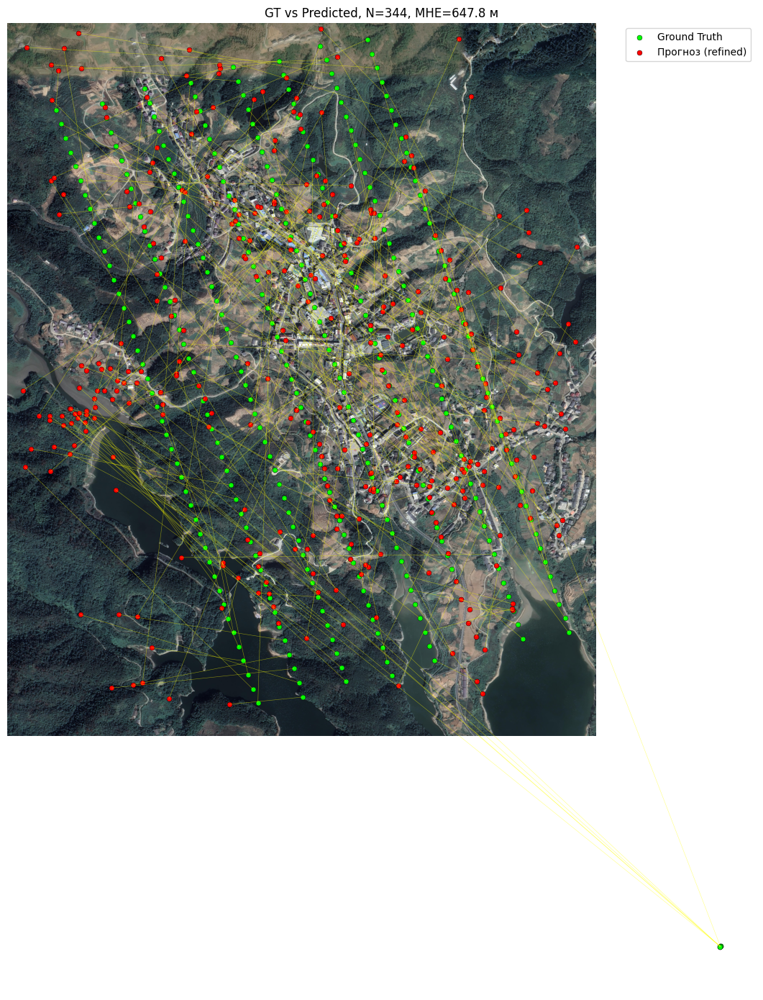

In [ ]:
fig, ax = plt.subplots(figsize=(14, 14))
display_img = cv2.resize(img_map_rgb, (map_w // 4, map_h // 4))
ax.imshow(display_img, extent=[0, map_w, map_h, 0])

with rasterio.open(SAT_MAP_PATH) as dataset:
    gt_px = np.array([dataset.index(lon, lat) for lat, lon in drone_gt_coords])
    pred_px = np.array([dataset.index(lon, lat) for lat, lon in refined_pred_coords])

for i in range(len(filenames)):
    ax.plot([gt_px[i, 1], pred_px[i, 1]], [gt_px[i, 0], pred_px[i, 0]], c="yellow", lw=0.4, alpha=0.5)
ax.scatter(gt_px[:, 1], gt_px[:, 0], c="lime", s=25, label="Ground Truth", edgecolors="black", linewidths=0.3)
ax.scatter(pred_px[:, 1], pred_px[:, 0], c="red", s=25, label="Прогноз (refined)", edgecolors="black", linewidths=0.3)

ax.set_title(f"GT vs Predicted, N={len(filenames)}, MHE={refined_errors.mean():.1f} м")
ax.legend(); ax.axis('off')
plt.tight_layout()
plt.savefig("gt_vs_pred_map.png", dpi=150)
plt.show()

Як бачимо з цієї карти, найбільші помилки модель робить в лісних масивах та річках, при цьому доволі точно визначає положення в місцях з унікальними будівлями та дорогами.

## Аналіз 5 найкращих і 5 найгірших прогнозів

Виключено з аналізу 6 кадрів, чия GT-точка поза межами карти 
5 НАЙКРАЩИХ прогнозів


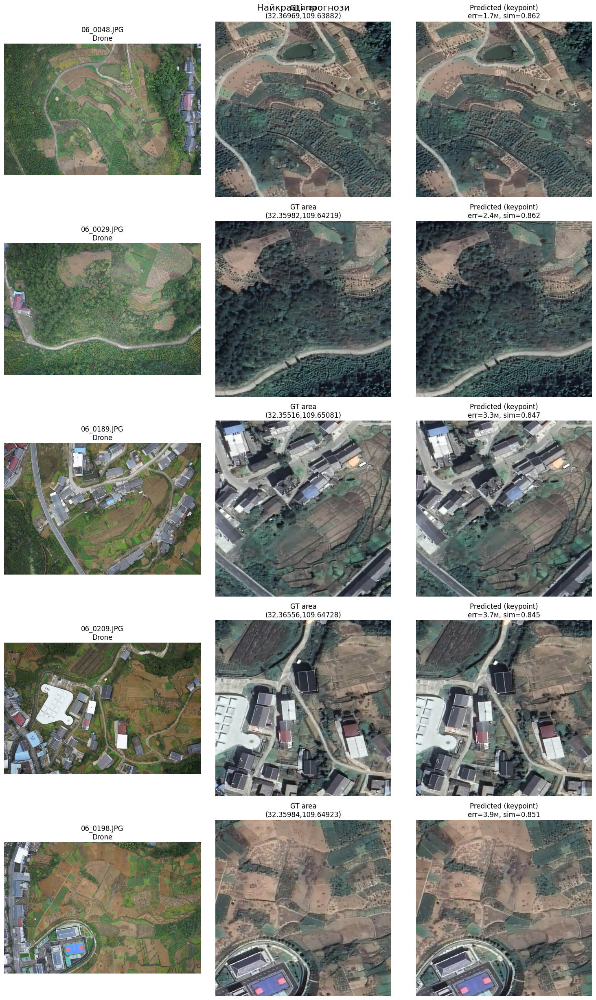

5 НАЙГІРШИХ прогнозів


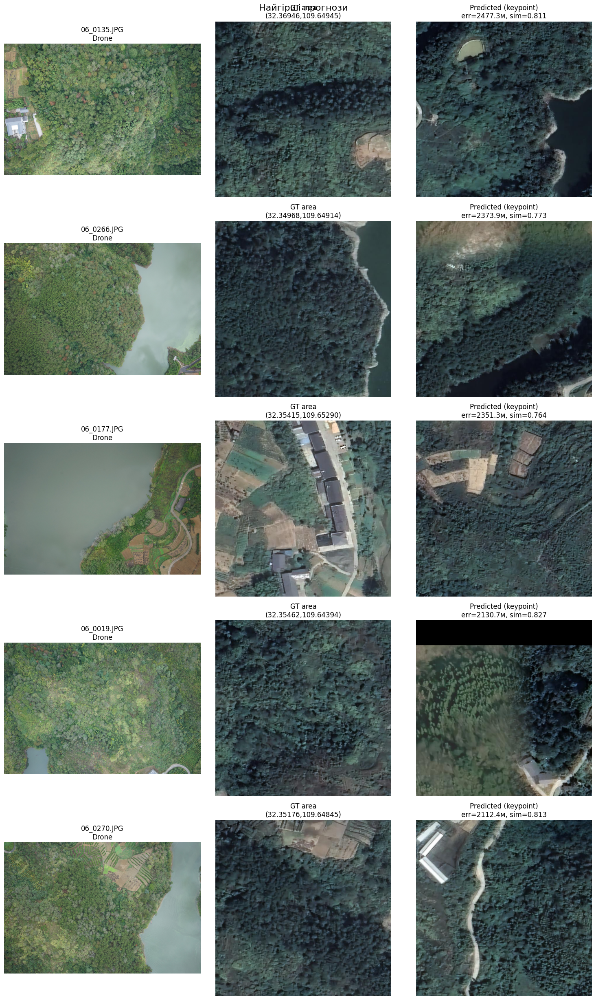

06_0135.JPG: error=2477.3м, similarity=0.811, keypoint_used=True, n_inliers=7
06_0266.JPG: error=2373.9м, similarity=0.773, keypoint_used=True, n_inliers=6
06_0177.JPG: error=2351.3м, similarity=0.764, keypoint_used=True, n_inliers=9
06_0019.JPG: error=2130.7м, similarity=0.827, keypoint_used=True, n_inliers=7
06_0270.JPG: error=2112.4м, similarity=0.813, keypoint_used=True, n_inliers=6


In [ ]:
with rasterio.open(SAT_MAP_PATH) as dataset:
    gt_rows_cols = np.array([dataset.index(lon, lat) for lat, lon in drone_gt_coords])

gt_visible_mask = (
    (gt_rows_cols[:, 0] >= 0) & (gt_rows_cols[:, 0] < map_h) &
    (gt_rows_cols[:, 1] >= 0) & (gt_rows_cols[:, 1] < map_w)
)

n_invisible = (~gt_visible_mask).sum()
if n_invisible > 0:
    print(f"Виключено з аналізу {n_invisible} кадрів, чия GT-точка поза межами карти "
)

visible_idx = np.where(gt_visible_mask)[0]

sorted_idx = visible_idx[np.argsort(refined_errors[visible_idx])]
best_idx, worst_idx = sorted_idx[:5], sorted_idx[-5:][::-1]
best_idx, worst_idx = sorted_idx[:5], sorted_idx[-5:][::-1]

def show_case_analysis(idx_list, title):
    fig, axes = plt.subplots(len(idx_list), 3, figsize=(15, 5 * len(idx_list)))

    if len(idx_list) == 1:
        axes = np.expand_dims(axes, 0)

    with rasterio.open(SAT_MAP_PATH) as dataset:
        for row, i in enumerate(idx_list):
            fname = filenames[i]
            drone_img = Image.open(os.path.join(DRONE_DIR, fname)).convert('RGB')
            gt_lat, gt_lon = drone_gt_coords[i]
            p_lat, p_lon = refined_pred_coords[i]

            gt_row, gt_col = dataset.index(gt_lon, gt_lat)
            p_row, p_col = dataset.index(p_lon, p_lat)

            def crop(r, c, s=600):
                crop_img = np.zeros((s, s, 3), dtype=np.uint8)

                half = s // 2
                r, c = int(r), int(c)

                y_map_start = max(0, r - half)
                y_map_end = min(map_h, r + half)
                x_map_start = max(0, c - half)
                x_map_end = min(map_w, c + half)

                if y_map_start >= y_map_end or x_map_start >= x_map_end:
                    return crop_img

                y_crop_start = half - (r - y_map_start)
                y_crop_end = y_crop_start + (y_map_end - y_map_start)

                x_crop_start = half - (c - x_map_start)
                x_crop_end = x_crop_start + (x_map_end - x_map_start)

                crop_img[y_crop_start:y_crop_end, x_crop_start:x_crop_end] = \
                    img_map_rgb[y_map_start:y_map_end, x_map_start:x_map_end]

                return crop_img

            axes[row, 0].imshow(drone_img)
            axes[row, 0].set_title(f"{fname}\nDrone")
            axes[row, 0].axis('off')

            axes[row, 1].imshow(crop(gt_row, gt_col))
            axes[row, 1].set_title(f"GT area\n({gt_lat:.5f},{gt_lon:.5f})")
            axes[row, 1].axis('off')

            refined_flag = "keypoint" if refinement_used[i] else "fallback (embedding)"

            axes[row, 2].imshow(crop(p_row, p_col))
            axes[row, 2].set_title(f"Predicted ({refined_flag})\nerr={refined_errors[i]:.1f}м, sim={similarities[i,0]:.3f}")
            axes[row, 2].axis('off')

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()
print("5 НАЙКРАЩИХ прогнозів")
show_case_analysis(best_idx, "Найкращі прогнози")

print("5 НАЙГІРШИХ прогнозів")
show_case_analysis(worst_idx, "Найгірші прогнози")

for i in worst_idx:
    print(f"{filenames[i]}: error={refined_errors[i]:.1f}м, similarity={similarities[i,0]:.3f}, "
          f"keypoint_used={refinement_used[i]}, n_inliers={n_inliers_list[i]}")

Як ми можемо бачити з цих кадрів, модель доволі непогано справляється з визначенням положення, якщо на фотографії знаходяться будинки, дороги, тощо, на що можна звернути увагу при визначенні положення.

Також модель погано справляється з фотографіями лісів, річок, озер, через велику кількість невизначенності та неоднорідних пікселів.

З візуалізації були виключені фотографія, які знаходяться поза межами супутникового знімку, оскільки правильного співставлення вона знайти навіть теоретично не зможе, проте ці випадки не були виключенні з метрики, як того і потребує завдання.

# Висновки

##Швидкодія:

3.16 с на одне фото.

У реальних умовах відсутності GPS цього цілком достатньо для використання алгоритму як глобального якоря. Система може працювати в гібридному режимі: IMU бере на себе керування в реальному часі, а візуальна модель раз на 3 секунди оновлює абсолютні координати, компенсуючи накопичену похибку IMU.

##Точність:


*   647 м MHE.
*   401 м медіани.

Цей результат покращив базовий приклад із технічного завдання: MHE зменшено на 169 м, а медіанну похибку — на 308 м. Зниження похибки досягнуто завдяки використанню нейромережі LoFTR як надбудови над DINOv2. LoFTR ефективно знаходить локальні піксельні збіги на визначених тайлах, що дозволяє отримувати точні координати замість прив'язки до центру тайла. Більшість залишкових значних похибок генеруються на візуально однорідних ділянках (густі ліси, водні поверхні), де унікальні ознаки для локалізації відсутні.

## Шляхи для покращення:


* Оновлення архітектури ембеддера: Використання новішої моделі DINOv3 має потенціал для кращого розуміння глобального контексту. Проте на даному етапі повноцінні версії цієї моделі занадто великі для запуску в середовищі Google Colab, а доступні урізані версії демонструють меншу стабільність порівняно з перевіреним DINOv2-base.

* Донавчання через LoRA: Донавчання DINOv2 на інших наборах даних за допомогою Contrastive Loss потенційно зробить модель стійкішою до зміни масштабу та перспективи. Однак це потребує значних апаратних ресурсів та часу, що виходить за межі поточних можливостей.

* Фільтрація треку: Впровадження алгоритмів згладжування дозволить системі ігнорувати стрибки координат при прольоті над лісами, спираючись на інерцію руху, що буде більш корисним при постійному оновленні положення дрона, а не одноразовому визначенню положення.

##Обґрунтування технічних рішень


* Вибір DINOv2 для Coarse-пошуку: На відміну від класичних класифікаторів чи моделей типу CLIP, які сильно прив'язані до текстових описів, архітектура DINOv2 тренувалася методом самонавчання. Це робить її однією з найоптимальніших для роботи з нетиповими ракурсами, такими як супутникові знімки.

* Використання LoFTR замість класичного ORB/SIFT: Класичні детектори ключових точок (ORB, SIFT) працюють виключно на основі локальних градієнтів пікселів. Вони виявилися неефективними через значну різницю(ракурс, колір, пора року, рослиність) між фото з дрона та супутниковою картою. LoFTR (Local Feature Matching with Transformers) є detector-free методом: він використовує механізми глобальної уваги, що дозволяє знаходити збіги навіть на ділянках з бідною текстурою.

* Параметри тайлінгу (512x512, крок 256): Розмір вікна обрано для забезпечення достатнього візуального контексту . Крок у 256 пікселів забезпечує перекриття тайлів на 50%. Зменшення кроку до 128 пікселів давало незначний приріст середньої точності (10-15 метрів), але збільшувало базу тайлів у 4 рази, що значно ускладнювало пайплайн.